# 14 · Residence-time distributions

Real reactors are neither perfectly mixed nor perfectly plug-flow: some fluid short-circuits, some sits in
dead zones, and a tubular reactor has a velocity profile. The residence-time distribution, measured with a
tracer, characterises this without opening the vessel. This notebook extracts E(t) and F(t) from pulse and
step experiments, computes their moments, compares them with the ideal reactors, and diagnoses bypassing
and dead volume - starting from tracer data with the baseline drift real detectors have.

**What you will learn**
- extract E(t) and F(t) from pulse and step data
- correct baselines and compute moments
- compare measured RTDs with the ideal reactors
- diagnose dead volume and bypassing

**Before you start:** notebook 01  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import datasets, rtd
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## A pulse experiment

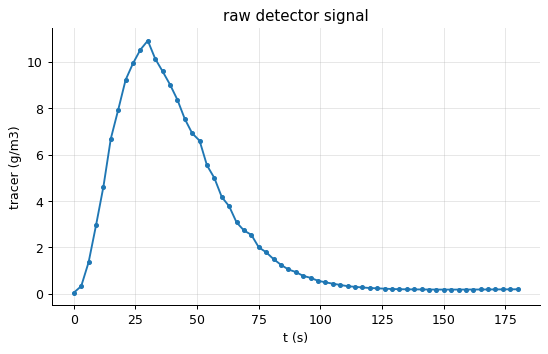

late-time baseline: [0.188 0.189 0.191 0.193 0.195] - the signal does not return to zero: offset and drift


In [2]:
d = pd.read_csv(datasets.path("rtd_tracer_pulse.csv"), comment="#")
fig, ax = plt.subplots(); ax.plot(d.t_s, d.C_g_m3, "o-", ms=3); ax.set(xlabel="t (s)", ylabel="tracer (g/m3)", title="raw detector signal"); plt.show()
print("late-time baseline:", np.round(d.C_g_m3.to_numpy()[-5:], 3), "- the signal does not return to zero: offset and drift")

The tail never quite reaches zero: detectors drift, and a baseline offset integrated over a long tail adds
spurious area at large t, inflating the mean residence time and, much more, the variance. Correcting the
baseline is the first step of every RTD analysis.

## Baseline correction and E(t)

raw                 : mean residence time   42.9 s, variance     715 s2, sigma^2/tau^2 = 0.388
baseline-corrected  : mean residence time   39.6 s, variance     409 s2, sigma^2/tau^2 = 0.260


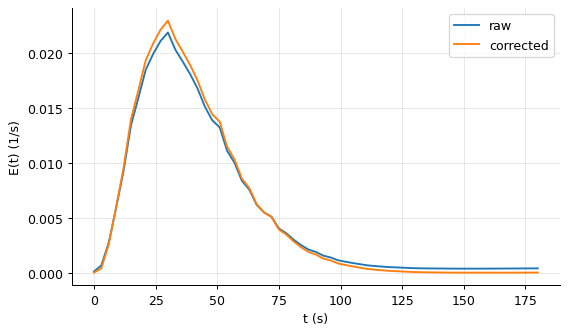

In [3]:
t, C = d.t_s.to_numpy(), d.C_g_m3.to_numpy()
tail = t > 140
base = np.polyfit(t[tail], C[tail], 1)                              # linear baseline from the tail
C_corr = np.maximum(C - np.polyval(base, t), 0.0)
E_raw, E_corr = rtd.E_from_pulse(t, C), rtd.E_from_pulse(t, C_corr)
for label, E in (("raw", E_raw), ("baseline-corrected", E_corr)):
    m = rtd.moments(t, E)
    print(f"{label:<20}: mean residence time {m['mean']:6.1f} s, variance {m['variance']:7.0f} s2, sigma^2/tau^2 = {m['variance']/m['mean']**2:.3f}")
fig, ax = plt.subplots(); ax.plot(t, E_raw, label="raw"); ax.plot(t, E_corr, label="corrected"); ax.set(xlabel="t (s)", ylabel="E(t) (1/s)"); ax.legend(); plt.show()

The correction moves the mean residence time by a few percent and the variance by much more, because the
variance weights the tail by $t^2$. The corrected mean of about 40 s is the vessel's volume over the flow
rate - a check that the tracer is inert and no fluid is trapped: a mean shorter than V/v$_0$ means dead
volume, longer means the tracer adsorbs.

## E(t), F(t) and the ideal reactors

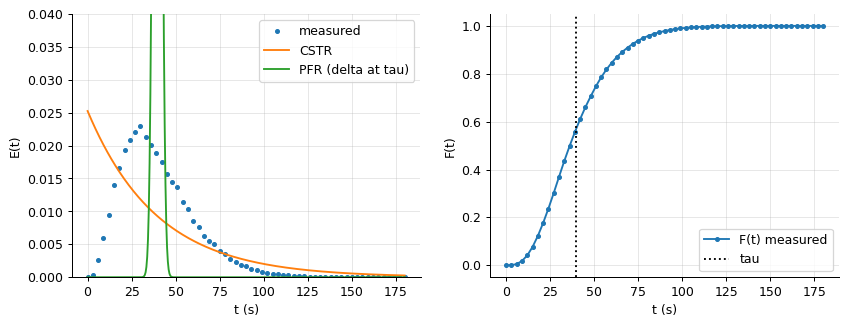

fraction of fluid leaving before 0.5 tau: 0.155; before 2 tau: 0.954 (CSTR: 0.393 and 0.865; PFR: 0 and 1)


In [4]:
m = rtd.moments(t, E_corr)
tau = m["mean"]
F = rtd.F_from_E(t, E_corr)
tt = np.linspace(0, 180, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(t, E_corr, "o", ms=3, label="measured"); ax[0].plot(tt, rtd.cstr_E(tt, tau), label="CSTR"); ax[0].plot(tt, rtd.pfr_E(tt, tau, 2.0), label="PFR (delta at tau)")
ax[0].set(xlabel="t (s)", ylabel="E(t)", ylim=(0, 0.04)); ax[0].legend()
ax[1].plot(t, F, "o-", ms=3, label="F(t) measured"); ax[1].axvline(tau, color="k", ls=":", label="tau"); ax[1].set(xlabel="t (s)", ylabel="F(t)"); ax[1].legend(); plt.show()
print(f"fraction of fluid leaving before 0.5 tau: {np.interp(0.5 * tau, t, F):.3f}; before 2 tau: {np.interp(2 * tau, t, F):.3f} (CSTR: 0.393 and 0.865; PFR: 0 and 1)")

The vessel is between the ideals: no fluid leaves immediately (unlike a CSTR) but the distribution is
broad (unlike a PFR). A CSTR's E(t) is an exponential and a PFR's a spike at $\tau$; the measured curve's
delayed peak and skewed tail are what the models of the next notebook - tanks in series, dispersion - will
quantify.

## Diagnosing faults from the RTD

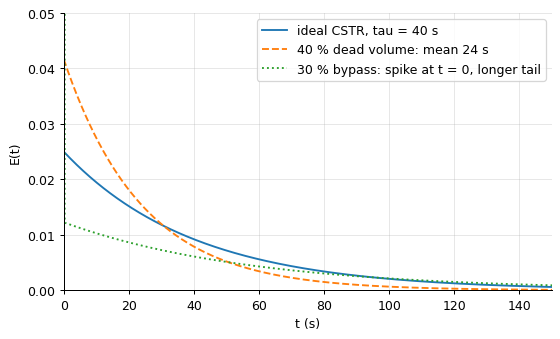

mean residence time with 40 % dead volume: 24.0 s against V/v0 = 40 s


In [5]:
tt = np.linspace(0, 200, 2001)
tau_design = 40.0
def bypass_E(frac, tau_eff):
    E = (1 - frac) * rtd.cstr_E(tt, tau_eff)
    E[:3] += frac / (tt[1] - tt[0]) / 3
    return E
E_dead = rtd.cstr_E(tt, 0.6 * tau_design)
fig, ax = plt.subplots()
ax.plot(tt, rtd.cstr_E(tt, tau_design), label="ideal CSTR, tau = 40 s")
ax.plot(tt, E_dead, "--", label="40 % dead volume: mean 24 s")
ax.plot(tt, bypass_E(0.3, tau_design / 0.7), ":", label="30 % bypass: spike at t = 0, longer tail")
ax.set(xlabel="t (s)", ylabel="E(t)", xlim=(0, 150), ylim=(0, 0.05)); ax.legend(); plt.show()
print(f"mean residence time with 40 % dead volume: {rtd.moments(tt, E_dead)['mean']:.1f} s against V/v0 = 40 s")

Two classic faults have signatures: dead volume shortens the mean residence time below $V/v_0$ (part of the
vessel does not participate); bypassing puts a spike of tracer at the outlet almost immediately and
lengthens the tail. Both waste reactor volume and both are found by a tracer test before anyone lifts a
manhole cover.

## Inside the algorithm: the mean residence time from E(t)

In [6]:
area = np.trapezoid(E_corr, t) if hasattr(np, "trapezoid") else np.trapz(E_corr, t)
tm = (np.trapezoid(t * E_corr, t) if hasattr(np, "trapezoid") else np.trapz(t * E_corr, t)) / area
print("by hand: mean residence time", round(tm, 2), "s; library:", round(rtd.moments(t, E_corr)["mean"], 2))

by hand: mean residence time 39.61 s; library: 39.61


## Exercises
1. A step experiment gives F(t). Simulate one from the corrected E(t) of the notebook (cumulative integral), add 2 % noise, and recover E(t) by differentiation. Why is the pulse experiment preferred for the variance and the step for the mean?
2. The vessel's design volume is 4.0 m3 and the flow 0.1 m3/s. Compare with the measured mean residence time. Is there dead volume, and how much? What would adsorption of the tracer on the walls do to the estimate?
3. **Implement it yourself:** write `moments(t, E)` returning mean, variance and skewness with trapezoidal integration and check it on the CSTR E(t) (skewness 2).